```markdown
# Project: Emotion Classification and Sentiment Analysis of Social Media Text

This project implements a comprehensive machine learning pipeline that uses:
1. **Unsupervised/Lexicon Sentiment Scoring**: VADER Sentiment Analysis and Dictionary-Based Scoring to generate continuous and categorical sentiment features.
2. **Supervised Classifier Models**: Logistic Regression, Support Vector Machine (SVM), and Multinomial Naive Bayes to classify the text into 6 target emotion classes:
   - 0: Sadness
   - 1: Joy
   - 2: Love
   - 3: Anger
   - 4: Fear
   - 5: Surprise
```

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

nltk.download('vader_lexicon')

# Load the dataset
file_path = '/content/DataSet - Complete.csv'
df = pd.read_csv(file_path)

# Display data shape and info
print(f"Dataset Shape: {df.shape}")
display(df.info())
display(df.head())

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


Dataset Shape: (19999, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19999 entries, 0 to 19998
Data columns (total 3 columns):
 #   Column                                         Non-Null Count  Dtype 
---  ------                                         --------------  ----- 
 0   0                                              19999 non-null  int64 
 1   i just feel really helpless and heavy hearted  19999 non-null  object
 2   4                                              19999 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 468.9+ KB


None

,0,i just feel really helpless and heavy hearted,4
0,1,ive enjoyed being able to slouch about relax a...,0
1,2,i gave up my internship with the dmrg and am f...,4
2,3,i dont know i feel so lost,0
3,4,i am a kindergarten teacher and i am thoroughl...,4
4,5,i was beginning to feel quite disheartened,0


```markdown
## Exploratory Data Analysis & Visualizations
Let's analyze the distribution of the target emotion label to understand class balance.
```

/tmp/ipykernel_1668/1610239123.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Emotion', order=emotion_map.values(), palette='viridis')


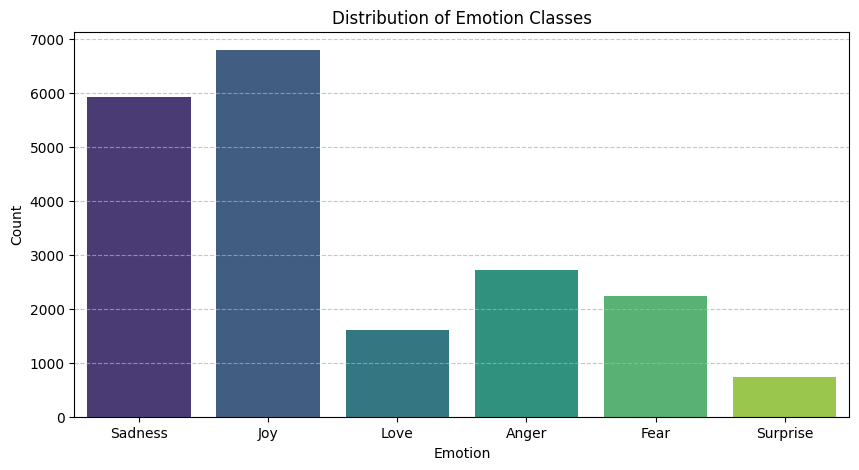

In [2]:
# Visualize Emotion Label Distribution
emotion_map = {
    0: 'Sadness',
    1: 'Joy',
    2: 'Love',
    3: 'Anger',
    4: 'Fear',
    5: 'Surprise'
}

# Map integer labels to corresponding names if the column is present
if 'label' in df.columns:
    df['Emotion'] = df['label'].map(emotion_map)
elif 'Label' in df.columns:
    df['Emotion'] = df['Label'].map(emotion_map)
else:
    # Try to find a column with numeric labels representing classes 0-5
    for col in df.columns:
        if df[col].nunique() == 6 or (df[col].min() == 0 and df[col].max() == 5):
            df['Emotion'] = df[col].map(emotion_map)
            df['label'] = df[col]
            break

plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='Emotion', order=emotion_map.values(), palette='viridis')
plt.title('Distribution of Emotion Classes')
plt.xlabel('Emotion')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

```markdown
## Unsupervised Feature Engineering: VADER Sentiment Scoring
We will extract real-valued compound scores, and categorize sentiment into negative (-1), neutral (0), and positive (1).
```

In [3]:
sia = SentimentIntensityAnalyzer()

# Find the text column dynamically
text_col = [col for col in df.columns if df[col].dtype == 'object' and col != 'Emotion'][0]
print(f"Using text column: '{text_col}' for analysis.")

# Apply VADER polarity scoring
df['vader_compound'] = df[text_col].apply(lambda x: sia.polarity_scores(str(x))['compound'])

# Categorize sentiment based on standard VADER thresholds
def categorize_sentiment(score):
    if score >= 0.05:
        return 1 # Positive
    elif score <= -0.05:
        return -1 # Negative
    else:
        return 0 # Neutral

df['vader_sentiment_label'] = df['vader_compound'].apply(categorize_sentiment)

# Display engineered sentiment features
display(df[[text_col, 'vader_compound', 'vader_sentiment_label']].head())

Using text column: 'i just feel really helpless and heavy hearted' for analysis.


,i just feel really helpless and heavy hearted,vader_compound,vader_sentiment_label
0,ive enjoyed being able to slouch about relax a...,0.6221,1
1,i gave up my internship with the dmrg and am f...,-0.4767,-1
2,i dont know i feel so lost,-0.4572,-1
3,i am a kindergarten teacher and i am thoroughl...,-0.7590,-1
4,i was beginning to feel quite disheartened,-0.5413,-1


```markdown
## Supervised Models: Emotion Classification
Let's extract TF-IDF vectors from our text and build our supervised learning classifiers.
```

In [4]:
# Feature extraction using TF-IDF
vectorizer = TfidfVectorizer(max_features=10000, stop_words='english')
X = vectorizer.fit_transform(df[text_col].astype(str))
y = df['label']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Define ML algorithms
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Support Vector Machine': LinearSVC(random_state=42),
    'Multinomial Naive Bayes': MultinomialNB()
}

# Training and evaluation
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    print(f"=== {name} Performance ===")
    print(f"Accuracy: {accuracy_score(y_test, preds):.4f}")
    print(classification_report(y_test, preds, target_names=[emotion_map[i] for i in sorted(y.unique())]))
    print("\n")

=== Logistic Regression Performance ===
Accuracy: 0.8655
              precision    recall  f1-score   support

     Sadness       0.90      0.92      0.91      1183
         Joy       0.83      0.95      0.89      1358
        Love       0.88      0.62      0.73       321
       Anger       0.91      0.83      0.87       544
        Fear       0.83      0.78      0.81       446
    Surprise       0.88      0.54      0.67       148

    accuracy                           0.87      4000
   macro avg       0.87      0.77      0.81      4000
weighted avg       0.87      0.87      0.86      4000



=== Support Vector Machine Performance ===
Accuracy: 0.8800
              precision    recall  f1-score   support

     Sadness       0.92      0.93      0.92      1183
         Joy       0.88      0.92      0.90      1358
        Love       0.83      0.74      0.78       321
       Anger       0.91      0.86      0.88       544
        Fear       0.81      0.83      0.82       446
    Surprise 